<a href="https://colab.research.google.com/github/lavanyar2025cse/FDS-EXPERIMENTS-250701385/blob/main/FDS_EXP_16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

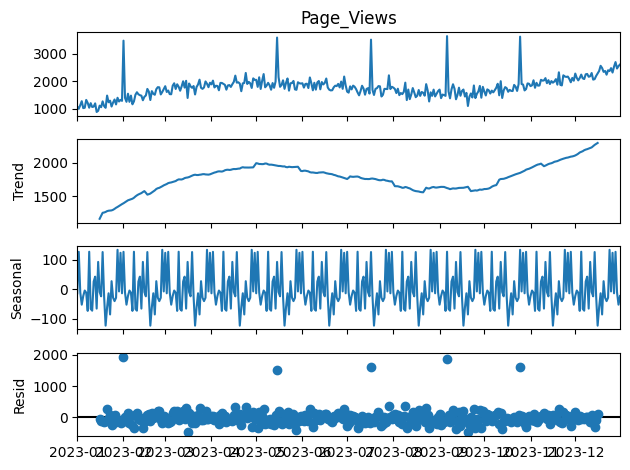

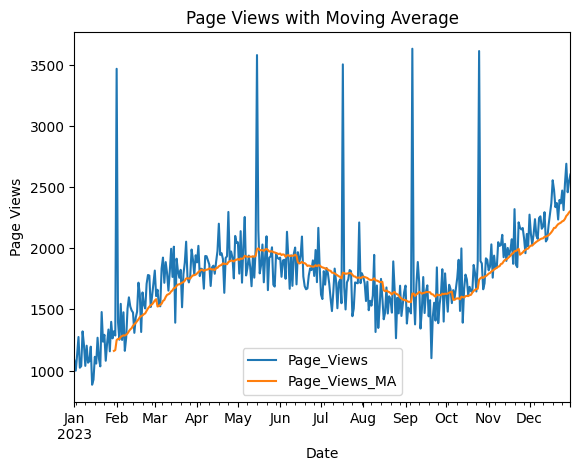

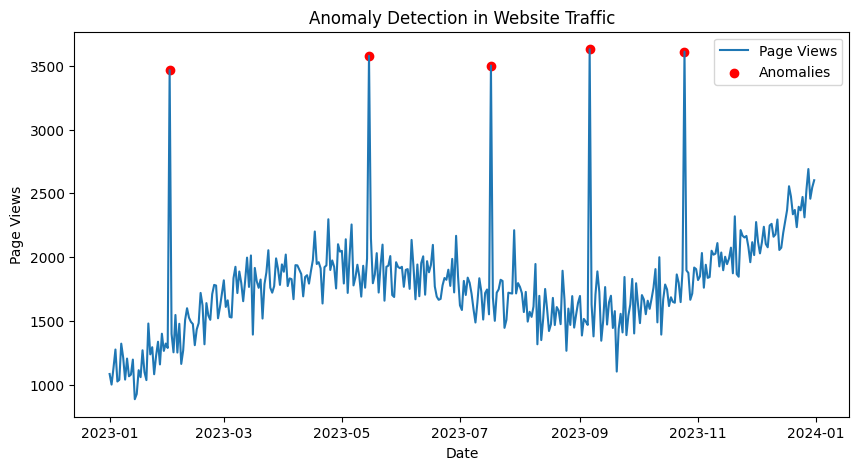

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

data = pd.read_csv(
    'website_traffic.csv',
    parse_dates=['Date'],
    index_col='Date'
)

decomposition = seasonal_decompose(
    data['Page_Views'],
    model='additive',
    period=30
)
decomposition.plot()
plt.show()

data['Page_Views_MA'] = data['Page_Views'].rolling(
    window=30
).mean()

data[['Page_Views', 'Page_Views_MA']].plot()
plt.title('Page Views with Moving Average')
plt.xlabel('Date')
plt.ylabel('Page Views')
plt.show()

data['Page_Views_Z'] = (
    data['Page_Views'] - data['Page_Views'].mean()
) / data['Page_Views'].std()

anomalies = data[data['Page_Views_Z'].abs() > 3]

plt.figure(figsize=(10, 5))
plt.plot(data.index, data['Page_Views'], label='Page Views')
plt.scatter(
    anomalies.index,
    anomalies['Page_Views'],
    color='red',
    label='Anomalies'
)
plt.title('Anomaly Detection in Website Traffic')
plt.xlabel('Date')
plt.ylabel('Page Views')
plt.legend()
plt.show()